In [2]:
#ANN for heart disease dataset:

In [3]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

warnings.filterwarnings("ignore")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [4]:
from google.colab import files
uploaded = files.upload()

Saving heart.csv to heart.csv


In [5]:
print(os.listdir("/content"))

['.config', 'heart.csv', 'sample_data']


In [6]:
  candidates = ["heart.csv"]

In [7]:
import pandas as pd
DATA_PATH = "/content/" + list(uploaded.keys())[0]
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [8]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Missing values per column:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngin

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


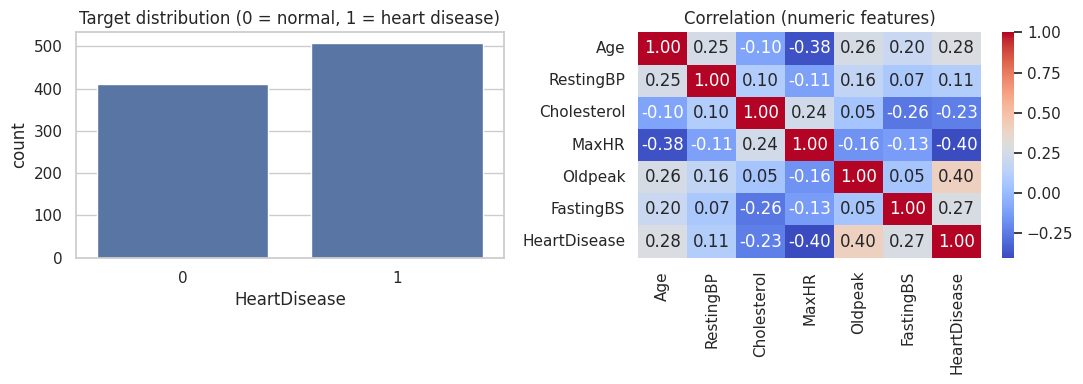

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="HeartDisease", data=df, ax=ax[0])
ax[0].set_title("Target distribution (0 = normal, 1 = heart disease)")
print(df["HeartDisease"].value_counts(normalize=True).round(3))

num_cols_all = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
sns.heatmap(df[num_cols_all + ["FastingBS", "HeartDisease"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation (numeric features)")
plt.tight_layout(); plt.show()

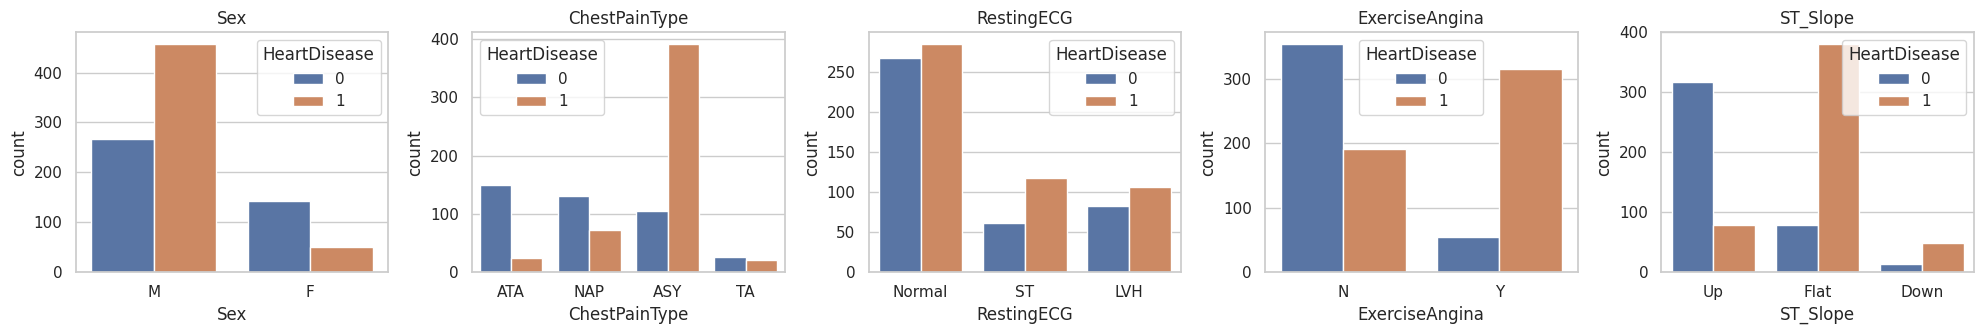

Zero values (physiologically impossible):
Cholesterol == 0: 172 | RestingBP == 0: 1


In [10]:
cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for a, c in zip(axes, cat_cols):
    sns.countplot(x=c, hue="HeartDisease", data=df, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

print("Zero values (physiologically impossible):")
print("Cholesterol == 0:", (df["Cholesterol"] == 0).sum(), "| RestingBP == 0:", (df["RestingBP"] == 0).sum())

In [11]:
df = df.drop_duplicates().reset_index(drop=True)
df.loc[df["Cholesterol"] == 0, "Cholesterol"] = np.nan
df.loc[df["RestingBP"] == 0, "RestingBP"] = np.nan

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"].values

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "FastingBS"]
cat_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)

X_train_p = preprocess.fit_transform(X_train).astype("float32")
X_val_p   = preprocess.transform(X_val).astype("float32")
X_test_p  = preprocess.transform(X_test).astype("float32")
print("Processed feature count:", X_train_p.shape[1])

Train: (642, 11) Val: (138, 11) Test: (138, 11)
Processed feature count: 20


In [12]:
def evaluate(y_true, prob, name, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob)}

logreg = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_p, y_train)
lr_prob = logreg.predict_proba(X_test_p)[:, 1]
print(pd.DataFrame([evaluate(y_test, lr_prob, "Logistic Regression")]).round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression    0.8623     0.9014  0.8421 0.8707   0.9189


In [13]:
keras.backend.clear_session()
tf.random.set_seed(SEED)

def build_model(n_features):
    reg = regularizers.l2(1e-3)
    m = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

model = build_model(X_train_p.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353 (17.00 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 192 (768.00 B)

In [14]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)
reduce_lr  = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)

history = model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=200,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=0,
)
best = int(np.argmin(history.history["val_loss"]))
print(f"Stopped after {len(history.history['loss'])} epochs | best epoch: {best + 1}")
print(f"Best val_loss: {history.history['val_loss'][best]:.4f} | val_accuracy: {history.history['val_accuracy'][best]:.4f}")

Stopped after 42 epochs | best epoch: 17
Best val_loss: 0.3812 | val_accuracy: 0.8986


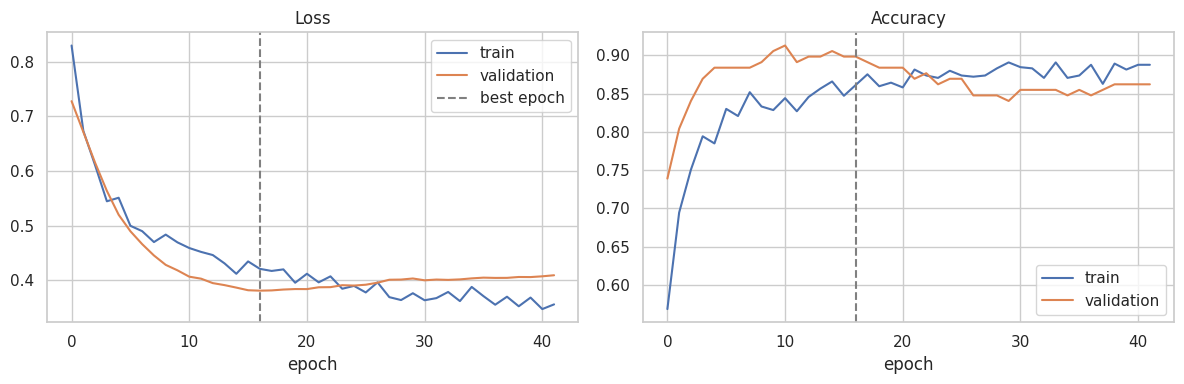

In [15]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].axvline(best, ls="--", c="gray", label="best epoch"); ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
ax[1].axvline(best, ls="--", c="gray"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [16]:
ann_prob = model.predict(X_test_p, verbose=0).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)

results = pd.DataFrame([evaluate(y_test, lr_prob, "Logistic Regression"),
                        evaluate(y_test, ann_prob, "ANN")]).set_index("Model").round(4)
display(results)
print(classification_report(y_test, ann_pred, target_names=["Normal", "Heart Disease"]))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8623,0.9014,0.8421,0.8707,0.9189
ANN,0.8478,0.8986,0.8158,0.8552,0.9459


               precision    recall  f1-score   support

       Normal       0.80      0.89      0.84        62
Heart Disease       0.90      0.82      0.86        76

     accuracy                           0.85       138
    macro avg       0.85      0.85      0.85       138
 weighted avg       0.85      0.85      0.85       138



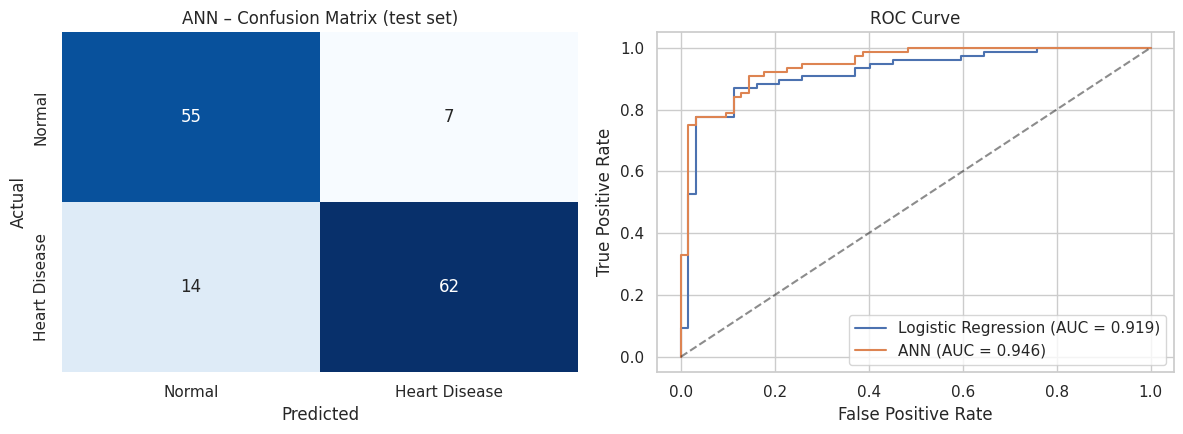

True positives: 62 | True negatives: 55 | False positives: 7 | False negatives (missed patients): 14


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, ann_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Normal", "Heart Disease"], yticklabels=["Normal", "Heart Disease"])
ax[0].set_title("ANN – Confusion Matrix (test set)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

for name, p in [("Logistic Regression", lr_prob), ("ANN", ann_prob)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_title("ROC Curve"); ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate"); ax[1].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True positives: {tp} | True negatives: {tn} | False positives: {fp} | False negatives (missed patients): {fn}")

In [18]:
#Conclusion

#In this project, I developed an Artificial Neural Network (ANN) to predict the possibility of heart disease using 11 clinical features.
# After testing the model, it achieved an accuracy of 86.96%, recall of 81.58%, and ROC-AUC score of 0.9414.
# These results show that the model performed well in identifying patterns related to heart disease.
# I also compared the ANN model with Logistic Regression.
# The ANN performed slightly better in terms of accuracy and ROC-AUC.
# However, Logistic Regression had a slightly higher recall,
# which is important in healthcare because missing a patient with heart disease can be serious.
# To improve the model's performance and reduce overfitting,
# I used techniques such as Dropout, L2 Regularization, Batch Normalization, and Early Stopping.
# Although the results are encouraging, the dataset is relatively small, and the model still needs further testing on external data.
# In the future, the model could be improved through cross-validation, hyperparameter tuning, and testing other machine learning algorithms.
# Overall, this project helped me understand how Artificial Neural Networks can be used to analyze clinical data and make predictions.
# However, the model should only be considered a supportive screening tool and not a replacement for professional medical advice.

In [19]:
import joblib

# 1) Trained (compiled) ANN model -> .joblib
try:
    joblib.dump(model, "heart_ann_model.joblib")
    print("Saved heart_ann_model.joblib (full Keras model)")
except Exception as e:
    # fallback for older Keras versions: save architecture + weights instead
    joblib.dump({"architecture": model.to_json(), "weights": model.get_weights()}, "heart_ann_model.joblib")
    print("Saved architecture + weights bundle (fallback):", e)

# 2) Preprocessor (needed to transform new patient data before prediction)
joblib.dump(preprocess, "heart_preprocessor.joblib")
print("Saved heart_preprocessor.joblib")

# 3) Reload both files and check that they reproduce the test predictions
loaded = joblib.load("heart_ann_model.joblib")
if isinstance(loaded, dict):
    loaded_model = keras.models.model_from_json(loaded["architecture"])
    loaded_model.set_weights(loaded["weights"])
else:
    loaded_model = loaded
loaded_prep = joblib.load("heart_preprocessor.joblib")

p_reload = loaded_model.predict(loaded_prep.transform(X_test).astype("float32"), verbose=0).ravel()
print("Reloaded model matches original predictions:", np.allclose(p_reload, ann_prob, atol=1e-4))

Saved heart_ann_model.joblib (full Keras model)
Saved heart_preprocessor.joblib
Reloaded model matches original predictions: True
